# Magic State Verification: Results

**Team:** The Cosmic Math Samurais · **Members:** Spencer Treadway, Milan Nathani, Taro Nagata · **Date:** November 22, 2026 · **Code:** https://github.com/SpencerTreadway/magic-state-verification

## Summary

We built a verifier for a single-qubit magic state |T⟩ = cos(π/8)|0⟩ + sin(π/8)|1⟩ that treats the state as unknown and sees only ±1 measurement outcomes. It covers four tasks: tomography (Level 1), fidelity estimation (Level 2), correction of readout errors (Level 3), and a statistically valid pass/fail certificate (Level 4). The key idea is that the fidelity F = ½(1 + (r_x + r_z)/√2) depends only on the X and Z components of the Bloch vector, so a shot measured in a random X or Z basis returns a single bounded variable s with F = ½ + E[s]/√2. That one fact gives us simple estimators, exact variance formulas, and finite-sample confidence bounds. The headline numbers are in the table below. The two main limitations are that Hoeffding's bound is conservative (about twice the shots a variance-aware bound would need) and that calibration trusts its reference states to be perfectly prepared (Section 7).

| Level | Method | Headline result |
|---|---|---|
| 1 | Bloch-vector tomography, projected onto the Bloch ball | RMS trace-distance error ≈ 0.021 (pure state) to 0.027 (mixed state) at N = 1000 shots per basis |
| 2 | X and Z only; equal, Neyman (adaptive) and random-basis allocation | RMSE ≈ 0.036 at N = 200 for F = 0.95 (theory 0.039) |
| 3 | Calibration on known eigenstates, with a bootstrap interval | RMSE 0.011 calibrated vs 0.051 uncorrected at N = 5000; best calibration fraction ≈ 0.35 (flat from 0.25 to 0.5) |
| 4 | Sequential Hoeffding test with alpha spending | mean shots to PASS at F = 1: ≈ 4,400; false-PASS rate 0 of 1000 runs at every F < 0.95 (Wilson upper bound 0.004; δ = 0.05) |

## Notebook map

| Section | Covers | Figures |
|---|---|---|
| 1 | Setup and configuration | none |
| 2 | Theory recap and sanity checks | none (assertions) |
| 3 | Level 1: reconstruct the state | Fig 1 |
| 4 | Level 2: estimate the fidelity | Fig 2, Fig 3 |
| 5 | Level 3: imperfect measurements | Fig 4, Fig 5, Fig 6 |
| 6 | Level 4: certification and optional stopping | Fig 7, Fig 8 |
| 7 | Limitations and failure modes | Fig 9 |
| 8 | Claims and evidence | none |
| 9 | Attribution and reproducibility | none |

**Running it.** This copy was run with `QUICK = False`, and all numbers quoted come from that single run. Setting `QUICK = True` runs in a few seconds and is noisy. Figures are saved to `notebook_figures/`.

## 1. Setup

Dependencies are numpy and matplotlib (versions listed in Section 9); the notebook also uses `sim.py` (the algorithm) and `notebook_utils.py` (plotting and simulation helpers only). Everything is seeded (`SEED = 12345`). `QUICK` only changes the number of Monte Carlo trials, never the methods. The estimators in `sim.py` receive only arrays of ±1 outcomes. The true state appears only inside the simulator and in the post-hoc scoring of each estimate.

In [2]:
import math
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import sim
import notebook_utils as nu

QUICK = False
SEED = 12345
if QUICK:
    TRIALS, CERT_TRIALS, OS_TRIALS, COV_TRIALS, N_BOOT = 300, 200, 200, 60, 150
else:
    TRIALS, CERT_TRIALS, OS_TRIALS, COV_TRIALS, N_BOOT = 2000, 1000, 500, 300, 200

SHOTS = [50, 100, 200, 500, 1000, 5000] # shot budgets for the Level 1-3 sweeps
THRESH, DELTA = 0.95, 0.05 # Level 4 requirement and error budget
MIN_CAL = 20 # minimum calibration shots per reference state
FIG_DIR = Path("notebook_figures")
FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

print(f"QUICK={QUICK}: trials={TRIALS}, certify trials={CERT_TRIALS}, optional-stopping trials={OS_TRIALS}, "
      f"coverage trials={COV_TRIALS} (bootstrap {N_BOOT})")

QUICK=False: trials=2000, certify trials=1000, optional-stopping trials=500, coverage trials=300 (bootstrap 200)


## 2. Theory recap and sanity checks

**Target and fidelity.** The target |T⟩ = cos(π/8)|0⟩ + sin(π/8)|1⟩ has Bloch vector n = (1, 0, 1)/√2. For ρ = ½(I + r·σ) we have F = ⟨T|ρ|T⟩ = tr(ρ|T⟩⟨T|) = ½(1 + r·n), because the identity part gives ½ and the Pauli part gives ½ r·n.

**Measurement model.** Measuring Pauli P returns ±1 with Pr(±1) = (1 ± r_P)/2. Each shot is a Bernoulli trial, so the sample mean r̂_P is unbiased with variance (1 − r_P²)/N.

**Why Y is not needed.** n has no y component, so F has no r_y and Y measurements cannot reduce the uncertainty in F. (Level 1 needs Y because it rebuilds the whole state.)

**One statistic for the fidelity.** If every shot is measured in X or Z with probability ½ and returns s = ±1, then E[s] = (r_x + r_z)/2 and therefore **F = ½ + E[s]/√2**. Each shot is an i.i.d. bounded variable, which is what makes the finite-sample confidence bounds in Level 4 simple.

**Assumptions.** A single qubit; i.i.d. shots (a fresh preparation each time, no drift); perfectly aligned measurement bases; readout error modelled by an affine map ⟨P⟩_obs = a + b⟨P⟩; perfectly prepared calibration states. Section 7 tests what happens when the last one fails.

Three checks follow; each has a one-line description.

**Check 1.** The Bloch-vector formula F = ½(1 + r·n) equals ⟨T|ρ|T⟩ computed directly from the density matrix, for random states.

In [3]:
# Check 1: the Bloch-vector fidelity formula equals <T|rho|T> computed from the density matrix.
errs = []
for _ in range(1000):
    r = nu.random_bloch(rng)
    errs.append(abs(nu.fidelity_from_rho(sim.rho_from_bloch(r)) - sim.fidelity(r)))
print(f"max |<T|rho|T> - F(r)| over 1000 random states: {max(errs):.2e}")
assert max(errs) < 1e-12

max |<T|rho|T> - F(r)| over 1000 random states: 2.22e-16


**Check 2.** The simulator reproduces Pr(+1 | P) = (1 + r_P)/2: the observed frequencies sit within sampling error of the prediction (z-scores near 0).

In [4]:
# Check 2: the simulator reproduces Pr(+1|P) = (1 + r_P)/2 (z-scores of the sample mean; all should be small).
zs = []
for _ in range(5):
    r = nu.random_bloch(rng)
    for i, P in enumerate("XYZ"):
        out = sim.measure(r, P, 200_000, rng)
        zs.append((out.mean() - r[i]) / (out.std(ddof=1) / math.sqrt(len(out))))
print("z-scores:", np.round(zs, 2))
assert max(abs(z) for z in zs) < 4.5

z-scores: [-0.9   0.57  1.44 -1.92  2.01  0.51 -0.84  0.6  -0.96 -0.1   0.47  0.24
 -1.09 -0.89 -0.08]


**Check 3.** The random-basis statistic: F = ½ + E[s]/√2 holds, and the fast sampler used for large sweeps has the same distribution as `sim.make_sampler`.

In [5]:
# Check 3: the random-basis statistic. (a) F = 1/2 + E[s]/sqrt(2); (b) the one-Bernoulli fast sampler used for the
# large sweeps is statistically equivalent to the faithful random-basis sampler in sim.py.
r = nu.state_zoo()["coherent rotation (F=0.95)"]
M = 400_000
s_faithful = sim.make_sampler(r, rng)(M)
s_fast = nu.fast_sampler(r, rng)(M)
m_true = 0.5 * (r[0] + r[2])
for name, s in (("faithful (sim.make_sampler)", s_faithful), ("fast (one Bernoulli)", s_fast)):
    z = (s.mean() - m_true) / (s.std(ddof=1) / math.sqrt(M))
    print(f"{name:30s} mean={s.mean():+.4f} (true {m_true:+.4f}, z={z:+.2f})  var={s.var():.4f} (theory {1 - m_true**2:.4f})  "
          f"F_hat={0.5 + s.mean() / math.sqrt(2):.4f} (true F={sim.fidelity(r):.4f})")
    assert abs(z) < 4.5

faithful (sim.make_sampler)    mean=+0.6350 (true +0.6364, z=-1.15)  var=0.5968 (theory 0.5950)  F_hat=0.9490 (true F=0.9500)
fast (one Bernoulli)           mean=+0.6372 (true +0.6364, z=+0.62)  var=0.5940 (theory 0.5950)  F_hat=0.9505 (true F=0.9500)


## 3. Level 1: reconstruct the state

**Method.** We measure X, Y and Z, take the sample means as r̂_P, and form ρ̂ = ½(I + r̂·σ). Sampling noise can push |r̂| above 1, which makes ρ̂ non-positive; in that case we rescale r̂ to unit length, which is the closest point of the Bloch ball in Euclidean distance and therefore gives a valid state. We chose this over maximum-likelihood or Bayesian estimation because for one qubit it is exact, needs no optimiser, and gives a closed-form error formula. MLE would remove the small bias that projection introduces near the surface of the ball, at the cost of more code.

**Why projection matters.** For pure and nearly pure states the raw estimate leaves the Bloch ball in roughly half of all trials (right panel of Fig 1), so the projection is not an edge case.

**Metric.** Trace distance ½‖ρ − ρ̂‖₁, which for qubits equals |r − r̂|/2 (checked in the cell below against the eigenvalue definition).

**What Fig 1 shows.** The error follows the 1/√N theory curve, with rms trace distance ≈ 0.021 for the pure state and 0.027 for the mixed state (|r| = 0.5) at N = 1000 per basis. The pure state is slightly *better* than the unprojected theory (0.021 vs 0.022) because the projection pulls overshooting estimates back toward the true state; for the mixed state the projection is never needed and the error equals the theory. Projection is needed in about 50% of trials for the pure state and 0% for the mixed one.

In [6]:
# The Bloch-vector shortcut |r - r_hat|/2 equals the eigenvalue definition of trace distance.
for _ in range(200):
    r1, r2 = nu.random_bloch(rng), nu.random_bloch(rng)
    td_rho = nu.trace_distance_rho(sim.rho_from_bloch(r1), sim.rho_from_bloch(r2))
    assert abs(td_rho - sim.trace_distance(r1, r2)) < 1e-12

# Every reconstructed density matrix must be Hermitian, trace one, and PSD.
states1 = {
    "pure |T> (|r|=1)": nu.target_state(),
    "mixed (|r|=0.5)": nu.random_bloch(rng, 0.5),
    "maximally mixed": np.zeros(3),
}
res1 = {}
for name, r in states1.items():
    rho_true = sim.rho_from_bloch(r)
    for N in SHOTS:                      # N shots in EACH of X, Y, Z
        td, projected = [], 0
        for _ in range(TRIALS):
            outs = [sim.measure(r, P, N, rng) for P in "XYZ"]
            projected += np.linalg.norm([o.mean() for o in outs]) > 1
            rho_hat = sim.reconstruct(*outs)
            assert nu.check_physical(rho_hat)
            td.append(nu.trace_distance_rho(rho_true, rho_hat))
        res1[(name, N)] = (math.sqrt(np.mean(np.square(td))), projected / TRIALS)
print("All reconstructed matrices were physical.")

All reconstructed matrices were physical.


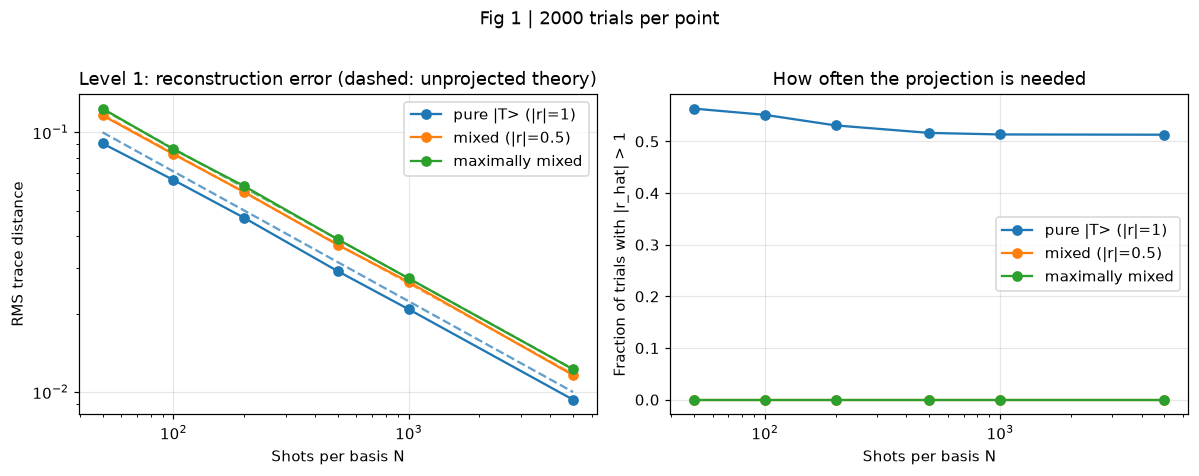

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, r in states1.items():
    rms = [res1[(name, N)][0] for N in SHOTS]
    line, = axes[0].plot(SHOTS, rms, "o-", label=name)
    theory = [0.5 * math.sqrt((3 - np.dot(r, r)) / N) for N in SHOTS]   # unprojected prediction
    axes[0].plot(SHOTS, theory, "--", color=line.get_color(), alpha=0.7)
    axes[1].plot(SHOTS, [res1[(name, N)][1] for N in SHOTS], "o-", label=name)
axes[0].set(xscale="log", yscale="log", xlabel="Shots per basis N", ylabel="RMS trace distance",
            title="Level 1: reconstruction error (dashed: unprojected theory)")
axes[1].set(xscale="log", xlabel="Shots per basis N", ylabel="Fraction of trials with |r_hat| > 1",
            title="How often the projection is needed")
axes[0].legend(); axes[1].legend()
fig.suptitle(f"Fig 1 | {TRIALS} trials per point", y=1.02)
save(fig, "fig1_level1.png"); plt.show()

## 4. Level 2: estimate the fidelity

**Method.** We skip Y entirely and use F̂ = ½(1 + (r̂_x + r̂_z)/√2), clipped to [0, 1]. We compare three ways of splitting N shots:
- **Equal:** N/2 shots in each of X and Z.
- **Adaptive (Neyman):** a pilot of N/20 shots per basis, then the remaining shots split in proportion to √(1 − r̂_P²). The pilot shots are reused in the final estimate.
- **Random basis:** each shot picks X or Z by a fair coin.

**Theory.**
- Equal: Var(F̂) = [(1 − r_x²) + (1 − r_z²)] / (4N).
- Neyman (best possible split): Var = (Σ_P √(1 − r_P²))² / (8N).
- Random basis: Var = (1 − m²)/(2N), with m = (r_x + r_z)/2. Relative to equal allocation it pays an extra (r_x − r_z)²/(8N), so it loses exactly when r_x ≠ r_z.

**Test states** (F in brackets): target (1.00), depolarized (0.95), coherent rotation (0.95), a state with r_y = 0.2 (≈ 0.99), and a mixed state (0.80). We include the r_y state to confirm that Y content does not change the result.

**Check against the problem statement.** The worked example from the PDF (84/16 X outcomes, 85/15 Z outcomes) gives F̂ = 0.988, matching the PDF.

**What Fig 2 and Fig 3 show.**
1. In the interior of the ball (F ≈ 0.95) the RMSE tracks the theory line: 0.036 observed vs 0.039 theory at N = 200 (depolarized state; 0.035 vs 0.035 for the coherent state).
2. Near F = 1 the RMSE falls *below* the theory line and the bias is negative. That is the clip at 1, not a better estimator (Section 7).
3. Adaptive allocation helps only where r_x ≠ r_z (the coherent state, large N), where it matches the Neyman prediction (0.0064 adaptive vs 0.0064 predicted, against 0.0070 for equal allocation, at N = 5000). At N = 50 it is worse for every state, because the pilot is only 2 shots per basis, and for the mixed state it is still worse at N = 200 (0.068 vs 0.046).
4. Random basis is slightly worse for the coherent state, as the (r_x − r_z)²/(8N) formula predicts.

**Shots for a target accuracy.** To reach ±0.01 at 95% confidence you need N ≈ (N·Var)·(1.96/0.01)², which for the F = 0.95 depolarized state is about 11,400 shots.

In [8]:
# Reproduce the PDF's worked example (84/16 X outcomes, 85/15 Z outcomes -> F_hat ~ 0.988).
x = np.array([1] * 84 + [-1] * 16)
z = np.array([1] * 85 + [-1] * 15)
F_example = float(sim.estimate_fidelity(x, z))
print("PDF example:", round(F_example, 4))
assert abs(F_example - 0.988) < 1e-3

PDF example: 0.9879


In [9]:
zoo = nu.state_zoo()
METHODS = ("equal", "adaptive", "random_basis")

def level2_trial(r, N, method):
    if method == "equal":
        nx = N // 2
        return float(sim.estimate_fidelity(sim.measure(r, "X", nx, rng), sim.measure(r, "Z", N - nx, rng)))
    if method == "adaptive":
        return float(sim.estimate_fidelity_adaptive(r, N, rng, pilot=max(1, N // 20)))
    return float(sim.estimate_fidelity_random_basis(r, N, rng))

t0 = time.time()
res2 = {}      # (state, N, method) -> (bias, bias_se, rmse, rmse_se)
for sname, r in zoo.items():
    F_true = sim.fidelity(r)
    for N in SHOTS:
        for m in METHODS:
            err = [level2_trial(r, N, m) - F_true for _ in range(TRIALS)]
            res2[(sname, N, m)] = nu.rmse_bias_se(err)
print(f"Level 2 sweep done in {time.time() - t0:.0f}s")

Level 2 sweep done in 4s


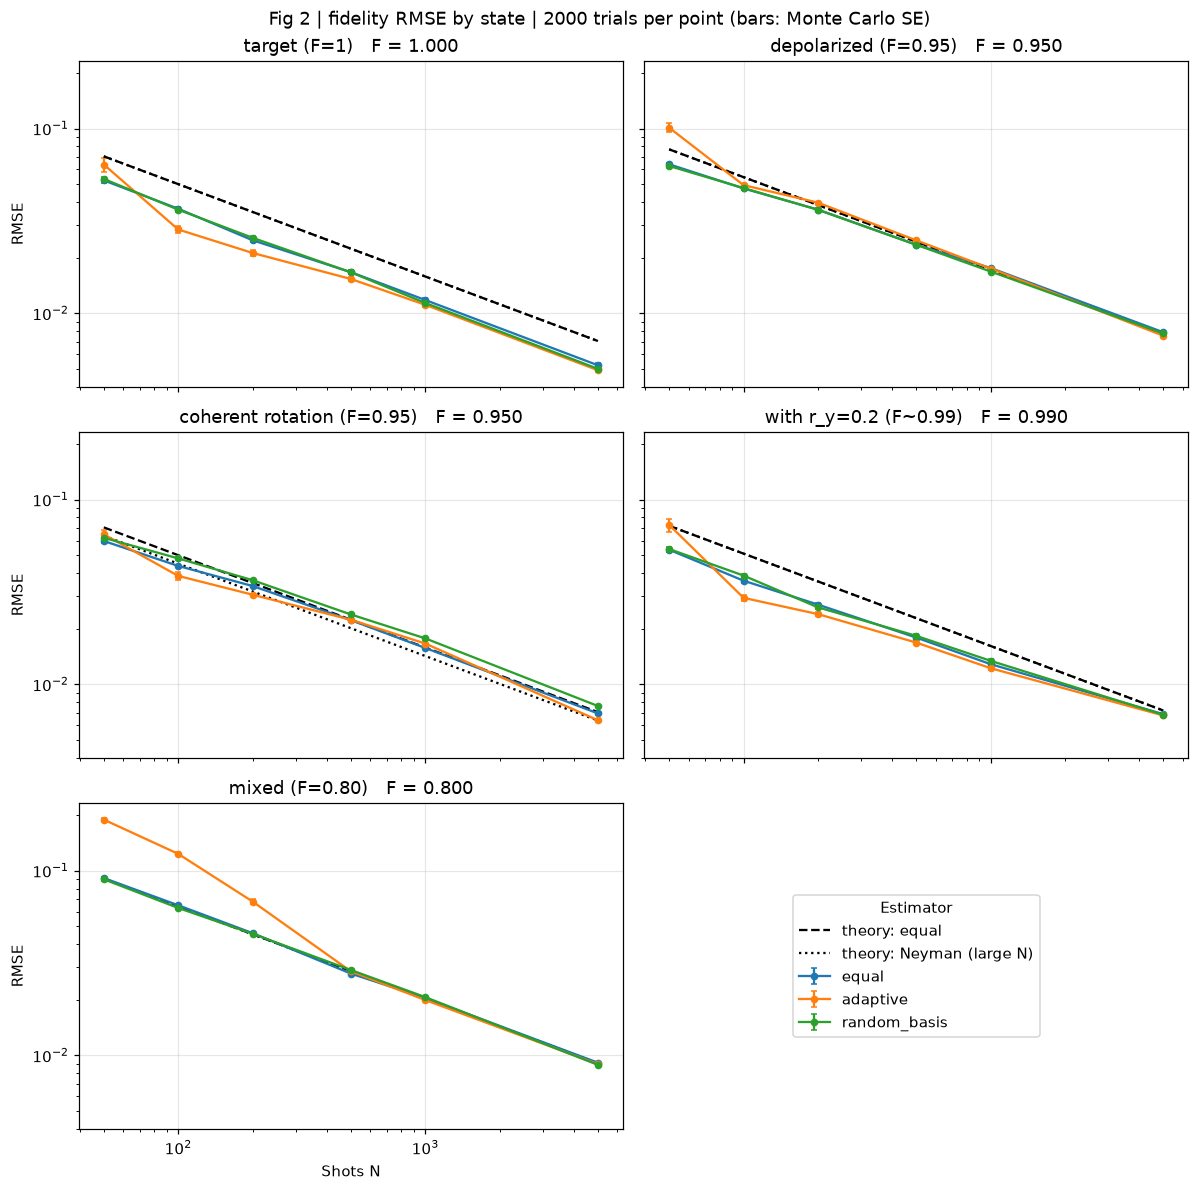

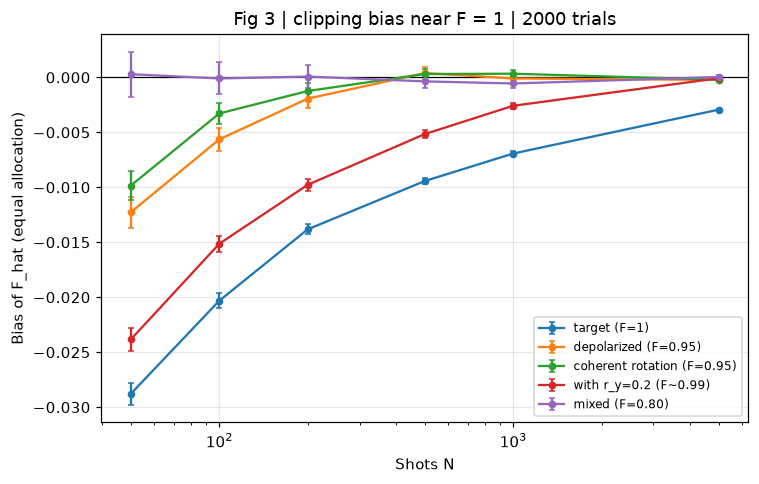

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(11, 11), sharex=True, sharey=True)
flat = axes.ravel()
for ax, (sname, r) in zip(flat, zoo.items()):
    for m in METHODS:
        rm = [res2[(sname, N, m)][2] for N in SHOTS]
        se = [res2[(sname, N, m)][3] for N in SHOTS]
        ax.errorbar(SHOTS, rm, yerr=se, marker="o", ms=4, capsize=2, label=m)
    ax.plot(SHOTS, [nu.sigma_equal(r, N) for N in SHOTS], "k--", label="theory: equal")
    ax.plot(SHOTS, [nu.sigma_adaptive(r, N) for N in SHOTS], "k:", label="theory: Neyman (large N)")
    ax.set(xscale="log", yscale="log", title=f"{sname}   F = {sim.fidelity(r):.3f}")
for ax in axes[:, 0]:
    ax.set_ylabel("RMSE")
for ax in axes[-1, :]:
    ax.set_xlabel("Shots N")
h, l = flat[0].get_legend_handles_labels()
flat[-1].axis("off"); flat[-1].legend(h, l, loc="center", title="Estimator")
fig.suptitle(f"Fig 2 | fidelity RMSE by state | {TRIALS} trials per point (bars: Monte Carlo SE)")
save(fig, "fig2_level2_rmse.png"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for sname in zoo:
    b = [res2[(sname, N, "equal")][0] for N in SHOTS]
    bse = [res2[(sname, N, "equal")][1] for N in SHOTS]
    ax.errorbar(SHOTS, b, yerr=bse, marker="o", ms=4, capsize=2, label=sname)
ax.axhline(0, color="k", lw=0.8)
ax.set(xscale="log", xlabel="Shots N", ylabel="Bias of F_hat (equal allocation)",
       title=f"Fig 3 | clipping bias near F = 1 | {TRIALS} trials")
ax.legend(fontsize=8)
save(fig, "fig3_level2_bias.png"); plt.show()

In [11]:
# Numbers to quote: observed RMSE vs theory at N = 200 and N = 5000.
print(f"{'state':30s} {'N':>5s} {'equal':>8s} {'theory':>8s} {'adaptive':>9s} {'Neyman':>8s} {'random':>8s} {'theory':>8s}")
for sname, r in zoo.items():
    for N in (200, 5000):
        print(f"{sname:30s} {N:5d} {res2[(sname, N, 'equal')][2]:8.4f} {nu.sigma_equal(r, N):8.4f} "
              f"{res2[(sname, N, 'adaptive')][2]:9.4f} {nu.sigma_adaptive(r, N):8.4f} "
              f"{res2[(sname, N, 'random_basis')][2]:8.4f} {nu.sigma_random_basis(r, N):8.4f}")

state                              N    equal   theory  adaptive   Neyman   random   theory
target (F=1)                     200   0.0248   0.0354    0.0212   0.0354   0.0256   0.0354
target (F=1)                    5000   0.0052   0.0071    0.0049   0.0071   0.0050   0.0071
depolarized (F=0.95)             200   0.0364   0.0386    0.0397   0.0386   0.0363   0.0386
depolarized (F=0.95)            5000   0.0079   0.0077    0.0076   0.0077   0.0078   0.0077
coherent rotation (F=0.95)       200   0.0341   0.0354    0.0306   0.0318   0.0366   0.0386
coherent rotation (F=0.95)      5000   0.0070   0.0071    0.0064   0.0064   0.0076   0.0077
with r_y=0.2 (F~0.99)            200   0.0270   0.0361    0.0240   0.0361   0.0261   0.0361
with r_y=0.2 (F~0.99)           5000   0.0069   0.0072    0.0068   0.0072   0.0068   0.0072
mixed (F=0.80)                   200   0.0459   0.0453    0.0681   0.0453   0.0455   0.0453
mixed (F=0.80)                  5000   0.0091   0.0091    0.0090   0.0091   0.00

## 5. Level 3: imperfect measurements

**Readout model.** The apparatus returns ⟨P⟩_obs = a + b⟨P⟩_true. Symmetric bit flips with probability ε are the special case a = 0, b = 1 − 2ε. We test a symmetric case (a, b) = (0, 0.90) and an asymmetric case (a, b) = (0.10, 0.85).

**Calibration.** For each basis P we prepare the +1 and −1 eigenstates, measure them, and estimate â = (m₊ + m₋)/2 and b̂ = (m₊ − m₋)/2. We then correct the state data with r̂_P = (mean − â)/b̂. Calibration shots are charged to the same budget: a fraction f_cal of N goes to calibration (split over four reference states) and the rest to the state, so the comparison with the uncorrected estimator is fair.

**Uncertainty.** The bootstrap resamples both the state outcomes and the calibration outcomes, so the interval includes calibration uncertainty. We check its coverage against the nominal 95% (Fig 6) instead of assuming it.

**Guard.** Each reference state gets at least 20 shots. With only 1 or 2 shots, b̂ can be exactly 0, which makes the correction divide by zero (table below).

**What Fig 4, 5 and 6 show.**
1. **Symmetric readout.** The uncorrected estimator is biased low by about 0.05 and its error plateaus at that floor; more shots do not help. The calibrated estimator has no floor and its error keeps falling like 1/√N: RMSE 0.0105 vs 0.0505 uncorrected at N = 5000 (calibrated bias −0.006, from clipping at 1).
2. **Calibration fraction (Fig 5).** The best f_cal is broad rather than sharp, roughly 0.25 to 0.5 (at N = 1000 the RMSE ratio is ≈ 0.43 across that range and rises to ≈ 0.55 at f_cal = 0.1). Too little calibration leaves b̂ noisy; too much starves the state measurement.
3. **Asymmetric readout.** Here the uncorrected estimator is competitive and in our runs even better: at N = 5000 its RMSE is 0.008 vs 0.0095 calibrated for F = 1, and 0.013 vs 0.014 for F = 0.90. Near the fixed point r* = a/(1 − b) ≈ 0.67 we have a + b·r ≈ r, so the offset and the contrast error cancel for states whose components sit near that value, and calibration then only adds variance. This is a property of these particular (a, b) values and states, not a general advantage of skipping calibration.
4. **Bootstrap coverage (Fig 6).** Coverage is 0.963 (target) and 0.970 (F = 0.95) at N = 5000 against a nominal 95%, each ±0.02 (Wilson). Across all N and both states it ranges from 0.92 to 0.98; the lowest point (0.917 at F = 0.95, N = 1000) is slightly below nominal, and we see no systematic small-N shortfall in this run, though with 300 trials per point we cannot rule out a small one (the percentile bootstrap is only asymptotically valid).

In [12]:
SCEN = {"symmetric": (0.0, 0.90), "asymmetric": (0.10, 0.85)}      # (a, b)
L3_STATES = {"symmetric": {"F=1": nu.target_state()},
             "asymmetric": {"F=1": nu.target_state(), "F=0.90": nu.on_axis_state(0.90)}}
CAL_FRACS = (0.1, 0.2, 0.4)

def l3_uncorrected(r, N, a, b):
    nx = N // 2
    return float(sim.estimate_fidelity(sim.measure(r, "X", nx, rng, a, b), sim.measure(r, "Z", N - nx, rng, a, b)))

def l3_calibrated(r, N, f, a, b):
    return sim.fidelity_from_data(sim.collect_data(r, N, f, rng, a, b))

t0 = time.time()
res3 = {}   # (scenario, state, method, N) -> (bias, bias_se, rmse, rmse_se)
for scen, (a, b) in SCEN.items():
    for sname, r in L3_STATES[scen].items():
        F_true = sim.fidelity(r)
        for N in SHOTS:
            res3[(scen, sname, "uncorrected", N)] = nu.rmse_bias_se(
                [l3_uncorrected(r, N, a, b) - F_true for _ in range(TRIALS)])
            for f in CAL_FRACS:
                if f * N / 4 < MIN_CAL:          # calibration guard
                    continue
                res3[(scen, sname, f"calibrated f={f}", N)] = nu.rmse_bias_se(
                    [l3_calibrated(r, N, f, a, b) - F_true for _ in range(TRIALS)])
print(f"Level 3 sweep done in {time.time() - t0:.0f}s")

Level 3 sweep done in 2s


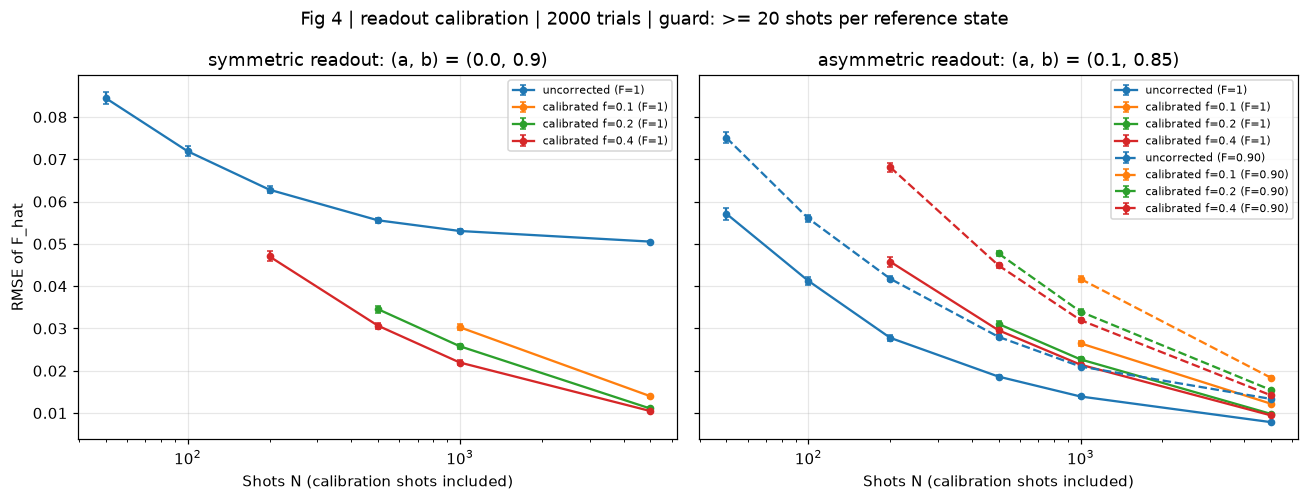

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
methods3 = ["uncorrected"] + [f"calibrated f={f}" for f in CAL_FRACS]
colors = dict(zip(methods3, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
for ax, scen in zip(axes, SCEN):
    a, b = SCEN[scen]
    for sname, ls in zip(L3_STATES[scen], ("-", "--")):
        for m in methods3:
            pts = [(N, res3[(scen, sname, m, N)]) for N in SHOTS if (scen, sname, m, N) in res3]
            if pts:
                ax.errorbar([p[0] for p in pts], [p[1][2] for p in pts], yerr=[p[1][3] for p in pts],
                            marker="o", ms=4, capsize=2, ls=ls, color=colors[m],
                            label=f"{m} ({sname})")
    ax.set(xscale="log", xlabel="Shots N (calibration shots included)",
           title=f"{scen} readout: (a, b) = ({a}, {b})")
axes[0].set_ylabel("RMSE of F_hat")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7)
fig.suptitle(f"Fig 4 | readout calibration | {TRIALS} trials | guard: >= {MIN_CAL} shots per reference state")
save(fig, "fig4_level3_rmse.png"); plt.show()

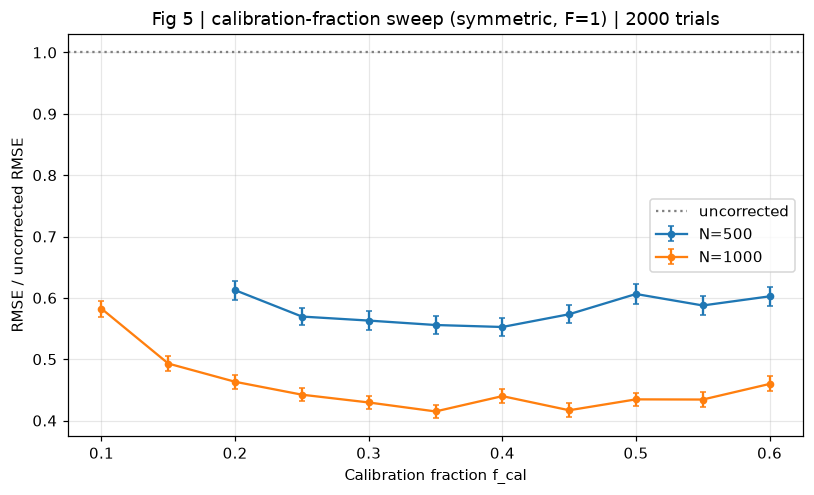

In [14]:
# Fig 5: calibration-fraction sweep (symmetric readout, target state), as a ratio to the uncorrected RMSE.
a, b = SCEN["symmetric"]
r = nu.target_state(); F_true = sim.fidelity(r)
fracs = np.linspace(0.1, 0.6, 11)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for N in (500, 1000):
    base = nu.rmse_bias_se([l3_uncorrected(r, N, a, b) - F_true for _ in range(TRIALS)])
    xs, ratio, ratio_se = [], [], []
    for f in fracs:
        if f * N / 4 < MIN_CAL:
            continue
        _, _, rm, rse = nu.rmse_bias_se([l3_calibrated(r, N, f, a, b) - F_true for _ in range(TRIALS)])
        xs.append(f); ratio.append(rm / base[2])
        ratio_se.append(rm / base[2] * math.hypot(rse / rm, base[3] / base[2]))
    ax.errorbar(xs, ratio, yerr=ratio_se, marker="o", ms=4, capsize=2, label=f"N={N}")
ax.axhline(1, color="gray", ls=":", label="uncorrected")
ax.set(xlabel="Calibration fraction f_cal", ylabel="RMSE / uncorrected RMSE",
       title=f"Fig 5 | calibration-fraction sweep (symmetric, F=1) | {TRIALS} trials")
ax.legend()
save(fig, "fig5_level3_fraction.png"); plt.show()

coverage sweep done in 18s


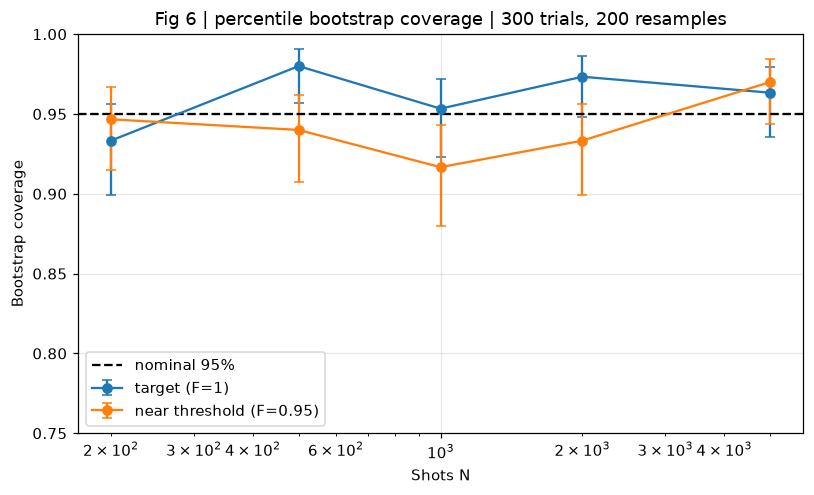

In [15]:
# Fig 6: coverage of the bootstrap interval for F (symmetric readout, f_cal = 0.4).
a, b = SCEN["symmetric"]
COV_N = [200, 500, 1000, 2000, 5000]
cov = {}
t0 = time.time()
for sname, r in {"target (F=1)": nu.target_state(), "near threshold (F=0.95)": nu.on_axis_state(0.95)}.items():
    F_true = sim.fidelity(r)
    for N in COV_N:
        hits = 0
        for _ in range(COV_TRIALS):
            data = sim.collect_data(r, N, 0.4, rng, a, b)
            lo, hi = sim.bootstrap_ci(data, rng, n_boot=N_BOOT)
            hits += lo <= F_true <= hi
        cov[(sname, N)] = hits
print(f"coverage sweep done in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for sname in ("target (F=1)", "near threshold (F=0.95)"):
    p = np.array([cov[(sname, N)] / COV_TRIALS for N in COV_N])
    ci = np.array([nu.wilson(cov[(sname, N)], COV_TRIALS) for N in COV_N])
    ax.errorbar(COV_N, p, yerr=[np.clip(p - ci[:, 0], 0, None), np.clip(ci[:, 1] - p, 0, None)], marker="o", capsize=3, label=sname)
ax.axhline(0.95, color="k", ls="--", label="nominal 95%")
ax.set(xscale="log", ylim=(0.75, 1.0), xlabel="Shots N", ylabel="Bootstrap coverage",
       title=f"Fig 6 | percentile bootstrap coverage | {COV_TRIALS} trials, {N_BOOT} resamples")
ax.legend()
save(fig, "fig6_level3_coverage.png"); plt.show()

In [16]:
# Why the guard exists: how often is the estimated contrast b_hat exactly 0 with very few calibration shots?
a, b = SCEN["symmetric"]
print("n_cal per reference state | P(b_hat = 0)")
for n in (1, 2, 3, 5, 10, 20):
    fails = sum(sim.calibrate("X", n, rng, a, b)[1] == 0 for _ in range(5000))
    print(f"{n:25d} | {fails / 5000:.4f}")

n_cal per reference state | P(b_hat = 0)
                        1 | 0.0974
                        2 | 0.0168
                        3 | 0.0018
                        5 | 0.0000
                       10 | 0.0000
                       20 | 0.0000


## 6. Level 4: certify the state

**Protocol.** Each shot is measured in X or Z at random and returns s = ±1, so F̂ = ½ + mean(s)/√2. We look at the data after N = 50, 100, 200, … shots (doubling). At look k we form a one-sided Hoeffding interval with error budget δ_k = 6δ/(π²k²), which sums to at most δ over all looks, and we keep the running intersection of the intervals. We declare **PASS** if the lower bound is ≥ 0.95 and **FAIL** if the upper bound is < 0.95; otherwise we continue to the 20,000-shot cap and report **INCONCLUSIVE**.

**Guarantee.** For any true F, P(false PASS) ≤ δ and P(false FAIL) ≤ δ, even though we stop whenever the data allow. This holds because the failure probability is spent across looks and combined with a union bound, so no choice of stopping time can inflate it.

**Why shots grow near the threshold.** The interval clears the threshold once N ≳ ln(1/δ_k)/gap², with gap = |F − 0.95|. Halving the gap quadruples the shots, and at gap = 0 no finite number suffices. This is the dotted prediction in Fig 7.

**Optional stopping.** If you check a fixed 95% interval after every batch and stop the first time it clears the threshold, the false-PASS rate climbs far above 5%, because the interval has many chances to be wrong. In Fig 8 the true fidelity is just below 0.95, so every PASS is an error. A naive normal rule that peeks every 50 shots has a false-PASS rate of 38% at F = 0.949. Spending the budget across looks reduces this to 11% for the normal rule, but the normal approximation is poor at small N, so it can still exceed δ and has no finite-sample guarantee. Hoeffding stays at 0% with a guarantee, at the cost of more shots (about 19,960 vs 7,640 on average for the naive rule at F = 0.949, i.e. it almost always runs to the cap there).

**What Fig 7 and 8 show.** There are no false PASSes below 0.95 (max 0 of 1000 at every F < 0.95, Wilson upper bound 0.004). FAIL becomes reliable (≥ 99%) by F ≈ 0.92 and PASS by F ≈ 0.98; between them the answer is INCONCLUSIVE, which is correct, because a state that close to the threshold cannot be certified at this budget. Mean shots to PASS at F = 1 is ≈ 4,400 (3,200 when the first passing look is the 7th, 6,400 when it is the 8th) and follows the 1/gap² trend. The tradeoff in Fig 8 is validity versus efficiency; we chose validity.

**Conservatism.** Hoeffding assumes worst-case variance, which is about twice the true variance at the target. A variance-aware bound (empirical Bernstein) or a betting confidence sequence would cut the shot count; we leave this as future work.

In [17]:
# Guard against drift: the instrumented version used in the demo notebook must agree with sim.certify.
for F in (0.90, 0.95, 0.99):
    r = nu.on_axis_state(F)
    out_sim = sim.certify(nu.fast_sampler(r, np.random.default_rng(7)))
    out_trace = nu.certify_trace(nu.fast_sampler(r, np.random.default_rng(7)))[:3]
    assert out_sim == out_trace, (F, out_sim, out_trace)
print("certify_trace matches sim.certify")

Fs = np.linspace(0.90, 1.0, 21)
cert = []   # (F, counts, mean shots)
t0 = time.time()
for F in Fs:
    r = nu.on_axis_state(F)
    counts = {"PASS": 0, "FAIL": 0, "INCONCLUSIVE": 0}
    shots = []
    for _ in range(CERT_TRIALS):
        decision, _, n = sim.certify(nu.fast_sampler(r, rng), thresh=THRESH, delta=DELTA)
        counts[decision] += 1
        shots.append(n)
    cert.append((F, counts, float(np.mean(shots))))
print(f"certification sweep done in {time.time() - t0:.0f}s")

below = [(F, c["PASS"]) for F, c, _ in cert if F < THRESH - 1e-9]
above = [(F, c["FAIL"]) for F, c, _ in cert if F > THRESH + 1e-9]
worst_fp = max(k for _, k in below) / CERT_TRIALS
worst_ff = max(k for _, k in above) / CERT_TRIALS
print(f"max false-PASS rate over F < {THRESH}: {worst_fp:.4f}  (Wilson 95% upper bound "
      f"{nu.wilson(max(k for _, k in below), CERT_TRIALS)[1]:.4f}, delta = {DELTA})")
print(f"max false-FAIL rate over F > {THRESH}: {worst_ff:.4f}")
assert worst_fp <= DELTA and worst_ff <= DELTA

certify_trace matches sim.certify
certification sweep done in 2s
max false-PASS rate over F < 0.95: 0.0000  (Wilson 95% upper bound 0.0038, delta = 0.05)
max false-FAIL rate over F > 0.95: 0.0020


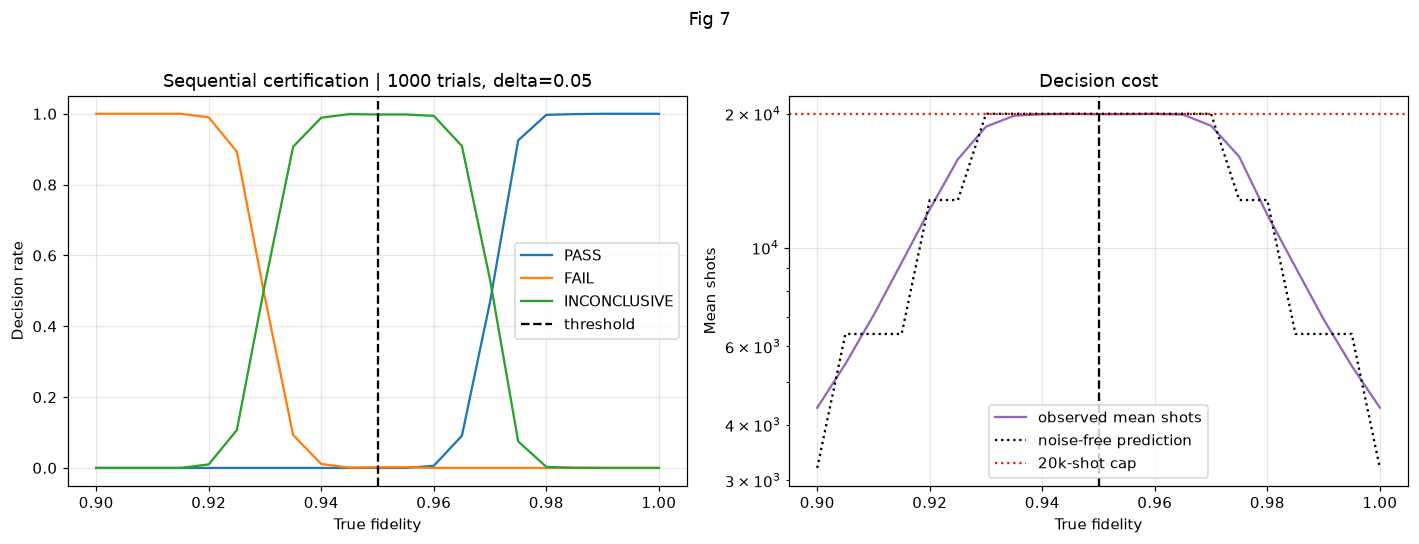

F      observed mean shots   noise-free prediction
0.900                4368           3200
0.905                5480           6400
0.910                7047           6400
0.915                9258           6400
0.920               12197          12800
0.975               16018          12800
0.980               11859          12800
0.985                9043           6400
0.990                6906           6400
0.995                5426           6400
1.000                4371           3200


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for key, color in (("PASS", "tab:blue"), ("FAIL", "tab:orange"), ("INCONCLUSIVE", "tab:green")):
    axes[0].plot(Fs, [c[key] / CERT_TRIALS for _, c, _ in cert], color=color, label=key)
axes[0].axvline(THRESH, color="k", ls="--", label="threshold")
axes[0].set(xlabel="True fidelity", ylabel="Decision rate",
            title=f"Sequential certification | {CERT_TRIALS} trials, delta={DELTA}")
axes[0].legend()

axes[1].plot(Fs, [m for _, _, m in cert], color="tab:purple", label="observed mean shots")
axes[1].plot(Fs, [nu.predicted_hoeffding_shots(F, THRESH, DELTA) for F in Fs], "k:", label="noise-free prediction")
axes[1].axhline(20000, color="tab:red", ls=":", label="20k-shot cap")
axes[1].axvline(THRESH, color="k", ls="--")
axes[1].set(yscale="log", xlabel="True fidelity", ylabel="Mean shots", title="Decision cost")
axes[1].legend()
fig.suptitle("Fig 7", y=1.02)
save(fig, "fig7_level4.png"); plt.show()

print("F      observed mean shots   noise-free prediction")
for F, _, m in cert:
    if abs(F - THRESH) >= 0.025:
        print(f"{F:.3f}  {m:18.0f}   {nu.predicted_hoeffding_shots(F, THRESH, DELTA):12d}")

optional-stopping experiment done in 1s


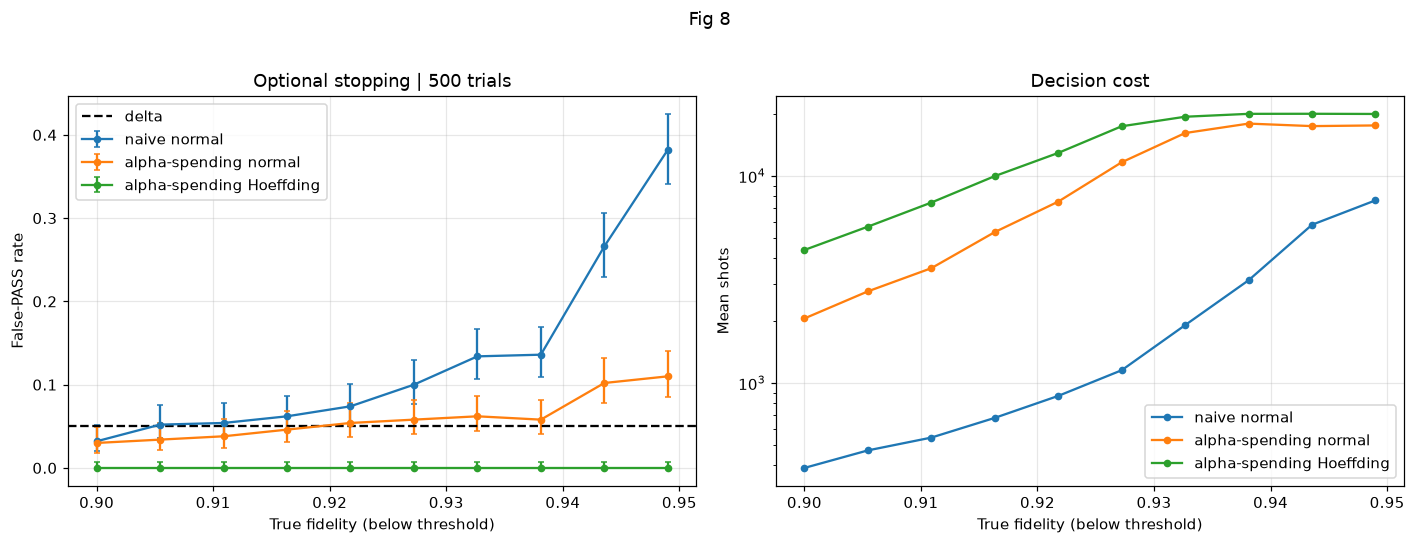

In [19]:
# Optional stopping: three rules on states just below the threshold (every PASS is a false PASS).
F_os = np.linspace(0.90, 0.949, 10)
t0 = time.time()
os_res = nu.optional_stopping_experiment(F_os, OS_TRIALS, rng, thresh=THRESH, delta=DELTA)
print(f"optional-stopping experiment done in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name in nu.RULE_NAMES:
    k = np.array(os_res[name]["passes"]); p = k / OS_TRIALS
    ci = np.array([nu.wilson(int(x), OS_TRIALS) for x in k])
    axes[0].errorbar(F_os, p, yerr=[np.clip(p - ci[:, 0], 0, None), np.clip(ci[:, 1] - p, 0, None)], marker="o", ms=4, capsize=2, label=name)
    axes[1].plot(F_os, os_res[name]["mean_shots"], "o-", ms=4, label=name)
axes[0].axhline(DELTA, color="k", ls="--", label="delta")
axes[0].set(xlabel="True fidelity (below threshold)", ylabel="False-PASS rate",
            title=f"Optional stopping | {OS_TRIALS} trials")
axes[1].set(yscale="log", xlabel="True fidelity (below threshold)", ylabel="Mean shots", title="Decision cost")
axes[0].legend(); axes[1].legend()
fig.suptitle("Fig 8", y=1.02)
save(fig, "fig8_optional_stopping.png"); plt.show()

## 7. Limitations and failure modes

1. **Clipping bias near F = 1.** We clip F̂ to [0, 1], so at the target the estimator is biased low (table below: raw vs clipped). The unclipped estimator is unbiased but returns unphysical values above 1.
2. **Calibration assumes perfect reference states.** If the "known" eigenstates are slightly impure, the contrast is mis-estimated and the error stops shrinking with N. Fig 9 shows the floor, which matches the predicted ½(r·n)(1/purity − 1): bias 0.0089 vs 0.0092 at purity 0.98, and 0.0227 vs 0.0237 at purity 0.95 (N = 5000).
3. **Too little calibration breaks the method.** With 1 to 2 shots per reference state, b̂ is exactly 0 in about 10% of runs (1 shot) and 1.7% (2 shots) (Section 5 table). Our guard requires at least 20 shots per reference state.
4. **Hoeffding is conservative.** Certification needs about twice the shots a variance-aware bound would. INCONCLUSIVE is the correct answer in a band around the threshold, and narrowing that band costs 1/gap² shots for any method.
5. **Normal intervals have no finite-sample guarantee.** Fig 8 shows the alpha-spending normal rule exceeding δ, and Fig 6 shows the percentile bootstrap slightly below nominal at some points (0.917 at F = 0.95, N = 1000).
6. **Unmodelled assumptions.** i.i.d. shots (no drift), a single qubit, an affine readout model, perfectly aligned bases, and calibration performed under the same conditions as the measurement. Level 4 is certified on raw data; we did not combine it with the Level 3 correction.

In [20]:
# (1) Clipping: compare the clipped estimator with the raw (unclipped) one at the target state, F = 1.
r = nu.target_state()
print(f"{'N':>5s} {'clipped bias':>13s} {'raw bias':>10s} {'P(raw F_hat > 1)':>17s}")
for N in SHOTS:
    clipped, raw = [], []
    for _ in range(TRIALS):
        nx = N // 2
        x, z = sim.measure(r, "X", nx, rng), sim.measure(r, "Z", N - nx, rng)
        f_raw = 0.5 * (1 + (x.mean() + z.mean()) / math.sqrt(2))
        raw.append(f_raw - 1.0)
        clipped.append(float(np.clip(f_raw, 0, 1)) - 1.0)
    print(f"{N:5d} {np.mean(clipped):13.4f} {np.mean(raw):10.4f} {np.mean(np.array(raw) > 0):17.2f}")

    N  clipped bias   raw bias  P(raw F_hat > 1)
   50       -0.0279     0.0001              0.55
  100       -0.0189     0.0019              0.52
  200       -0.0141     0.0001              0.53
  500       -0.0089    -0.0001              0.52
 1000       -0.0065    -0.0004              0.50
 5000       -0.0027     0.0004              0.53


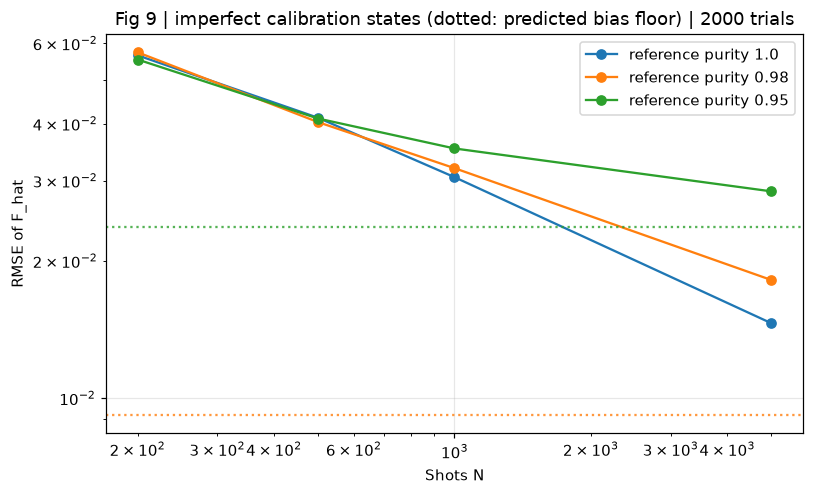

In [21]:
# (2) Imperfect calibration references: the "known" eigenstates are prepared with Bloch length `prep` < 1.
def collect_data_imperfect_refs(r, N, f_cal, a, b, prep):
    n_cal = max(1, int(round(f_cal * N / 4)))
    n_state = max(1, int(round((1 - f_cal) * N / 2)))
    return {
        "state": {P: sim.measure(r, P, n_state, rng, a, b) for P in "XZ"},
        "cal": {(P, s): sim.measure(prep * sim.eigenstate(P, s), P, n_cal, rng, a, b)
                for P in "XZ" for s in (+1, -1)},
    }

a, b = SCEN["symmetric"]
r = nu.on_axis_state(0.95); F_true = sim.fidelity(r)
Ns = [N for N in SHOTS if 0.4 * N / 4 >= MIN_CAL]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for prep in (1.0, 0.98, 0.95):
    rms = []
    for N in Ns:
        err = [sim.fidelity_from_data(collect_data_imperfect_refs(r, N, 0.4, a, b, prep)) - F_true
               for _ in range(TRIALS)]
        rms.append(nu.rmse_bias_se(err)[2])
    line, = ax.plot(Ns, rms, "o-", label=f"reference purity {prep}")
    floor = 0.45 * (1 / prep - 1)       # predicted bias: 0.5 * (r.n) * (1/prep - 1) with r.n = 0.9
    if floor > 0:
        ax.axhline(floor, color=line.get_color(), ls=":", alpha=0.8)
ax.set(xscale="log", yscale="log", xlabel="Shots N",  ylabel="RMSE of F_hat",
       title=f"Fig 9 | imperfect calibration states (dotted: predicted bias floor) | {TRIALS} trials")
ax.legend()
save(fig, "fig9_spam_floor.png"); plt.show()

## 8. Claims and evidence

Every claim made in the live demo is listed here with the figure and number that support it.

| # | Claim | Evidence | Number |
|---|---|---|---|
| 1 | The fidelity estimate needs only X and Z | Section 2, Fig 2 | RMSE ≈ 0.036 at N = 200 matches theory 0.039 (F = 0.95) |
| 2 | Neyman allocation helps when r_x ≠ r_z | Fig 2 (coherent panel) | 0.0064 vs 0.0070 (equal) at N = 5000, coherent state |
| 3 | Calibration removes the readout bias floor | Fig 4 (symmetric) | 0.0105 vs 0.0505 at N = 5000 |
| 4 | The bootstrap interval is close to nominal for large N | Fig 6 | coverage 0.963 / 0.970 ± 0.02 at N = 5000 |
| 5 | Certification never falsely passes (≤ δ) | Fig 7 | max false-PASS 0/1000 (Wilson upper 0.004) |
| 6 | Naive peeking is invalid; alpha spending reduces the error; Hoeffding guarantees it | Fig 8 | naive 38%, spending-normal 11%, Hoeffding 0% at F = 0.949 |
| 7 | Imperfect calibration states create an error floor | Fig 9 | 0.0227 vs predicted 0.0237 (purity 0.95) |

## 9. Attribution and reproducibility

### AI assistance

We used Claude (Anthropic) as an assistant during the hackathon for: (a) explaining the magic-state background and the challenge statement; (b) reviewing `sim.py` and `experiments.py` and suggesting changes, of which we adopted many that handled various error handlins tasks and corrections to logic; (c) drafting the structure of these notebooks and the helper module `notebook_utils.py`, which contains only plotting and simulation helpers. We wrote all comments/presentation scripts notes, and we ran, checked and take responsibility for all results. We validated the code with the assertion checks in Section 2, the comparison against the PDF's worked example, and the coverage and false-PASS experiments in Sections 5 and 6.

### Published methods

- Gidney, Shutty and Jones, *Magic state cultivation: growing T states as cheap as CNOT gates* (2024): the work behind the challenge. TEAM: verify details.
- Bravyi and Kitaev, *Universal quantum computation with ideal Clifford gates and noisy ancillas*, Phys. Rev. A 71, 022316 (2005): magic states and distillation.
- Gottesman, *The Heisenberg representation of quantum computers* (1998): Clifford operations alone are classically simulable.
- Hoeffding, *Probability inequalities for sums of bounded random variables*, J. Amer. Statist. Assoc. 58 (1963): the bound used in Level 4.
- Efron, *Bootstrap methods: another look at the jackknife*, Ann. Statist. 7 (1979): the bootstrap used in Level 3.
- Wald, *Sequential tests of statistical hypotheses* (1945), and Howard, Ramdas, McAuliffe and Sekhon, *Time-uniform, nonparametric, nonasymptotic confidence sequences*, Ann. Statist. (2021): background on optional stopping. Our alpha spending is the simpler union-bound version.
- Flammia and Liu, *Direct fidelity estimation from few Pauli measurements*, Phys. Rev. Lett. 106 (2011): related work on fidelity estimation without full tomography.

### External code

numpy and matplotlib (plus nbformat/nbclient only to build and run the notebooks). No other external code was used.

### Reproducibility

- Install: `pip install -r requirements.txt`
- Regenerate the experiment CSVs and figures: `python experiments.py` (runtime 59s)
- Run this notebook top to bottom with `QUICK = False` (runtime 32s)
- All seeds are fixed and printed (`SEED = 12345`).